# 12 — Why AlphaEarth cells need \(f_{\mathrm{res}}\) (not majority)

**Meeting 1 P0:** for a **10 m AlphaEarth cell**, prefer the **fraction of
residential building area** over majority class. Locked in
[`resi_def_v1`](../docs/residential_definition_v1.md).

This notebook is the AlphaEarth analogue of notebook 11’s “mixed GHSL under one
footprint” figure — except now **one cell** overlaps **several Overture buildings**.

```text
f_res(c) = sum(a_i * y_res_i) / sum(a_i) a_i = area(cell ∩ building_i)

hard label (τ = 0.7):
 f_res ≥ 0.7 → residential
 f_res ≤ 0.3 → non-residential
 else → mixed (exclude from binary metrics)
```

**Why not majority?** Two buildings touching a cell → majority is a coin flip /
tie-to-RES even when 88% of the cell area is a school.

**Writes.** `outputs/ae_f_res/` (figures + tables + `snapshot.json`).


## 0. Setup


In [1]:
from __future__ import annotations

import json
import os
import sys
import warnings
from pathlib import Path

%matplotlib inline

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from matplotlib.patches import Patch
from shapely import wkt as shapely_wkt
from tqdm.auto import tqdm

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda x: f"{x:0.4f}")

ROOT = Path(".").resolve()
for cand in [ROOT, *ROOT.parents]:
    if (cand / "docs" / "residential_definition_v1.md").exists():
        ROOT = cand
        break
os.chdir(ROOT)

OUT = ROOT / "outputs" / "ae_f_res"
FIG = OUT / "figures"
OUT.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)

TAU = 0.7
AOI = "NYC_NE"
UTM = 32618  # NYC local metres for intersection areas

RES_COLOR = "#2ca02c"
NRES_COLOR = "#d62728"
CELL_EDGE = "#1f77b4"

print("ROOT", ROOT)
print("τ =", TAU, "· AOI =", AOI)


ROOT /data/users/kv133/Alpha-Earth-Embeddings-Research
τ = 0.7 · AOI = NYC_NE


## 1. Load Overture buildings + AlphaEarth 10 m cells

Buildings carry `y_res` (`resi_def_v1` Building GT). Cells come from the bbox-grid
dataset (centers that fall inside footprints). We re-key cells by lon/lat so the
**same geographic 10 m pixel** can be scored against *all* overlapping buildings.


In [2]:
b = pd.read_parquet(ROOT / "datasets/building_bbox_grid/buildings.parquet")
sub = b[b["region"].astype(str) == AOI].copy()
gdf = gpd.GeoDataFrame(sub, geometry=sub["wkt"].map(shapely_wkt.loads), crs="EPSG:4326")
gdf_m = gdf.to_crs(UTM)
gdf_m["y_res"] = gdf_m["y_res"].astype(int)
print(f"Buildings in {AOI}: {len(gdf_m)}  RES={(gdf_m.y_res==1).sum()}  NRES={(gdf_m.y_res==0).sum()}")

cells = pd.read_parquet(
    ROOT / "datasets/building_bbox_grid/building_cells.parquet",
    columns=["id", "pixel_lon", "pixel_lat", "pixel_wkt", "pixel_size_m", "inside_polygon"],
)
cells = cells[cells["id"].isin(set(sub["id"])) & (cells["inside_polygon"] == True)].copy()
cells["key"] = (
    cells["pixel_lon"].round(6).astype(str) + "_" + cells["pixel_lat"].round(6).astype(str)
)
uniq = cells.drop_duplicates("key")[["key", "pixel_lon", "pixel_lat", "pixel_wkt", "pixel_size_m"]]
cg = gpd.GeoDataFrame(uniq, geometry=uniq["pixel_wkt"].map(shapely_wkt.loads), crs="EPSG:4326").to_crs(UTM)
print(f"Unique AE cells (inside footprints): {len(cg)}")


Buildings in NYC_NE: 1327  RES=337  NRES=990
Unique AE cells (inside footprints): 19422


## 2. Score every cell that hits ≥2 buildings of both classes

For each such cell compute:

- \(f_{\mathrm{res}}\) (area-weighted)
- **majority by building count** (tie → RES, same trap as a naive rule)
- hard label under τ = 0.7 (including **mixed**)


In [3]:
def hard_label(f_res: float, tau: float = TAU) -> str:
    if f_res >= tau:
        return "residential"
    if f_res <= 1.0 - tau:  # 0.3 when tau=0.7
        return "non_residential"
    return "mixed"


joined = gpd.sjoin(
    cg, gdf_m[["id", "y_res", "label", "class", "geometry"]], how="inner", predicate="intersects"
)

rows = []
details_by_key: dict = {}
for key, hit in tqdm(joined.groupby("key"), total=joined["key"].nunique(), desc="score cells"):
    bids = hit.drop_duplicates("id")
    if len(bids) < 2:
        continue
    if set(bids["y_res"].unique()) != {0, 1}:
        continue
    cell_geom = cg.loc[cg["key"] == key].geometry.iloc[0]
    parts = []
    for _, r in bids.iterrows():
        bgeom = gdf_m.loc[gdf_m["id"] == r["id"]].geometry.iloc[0]
        a = cell_geom.intersection(bgeom).area
        if a <= 0:
            continue
        parts.append(
            {
                "building_id": r["id"],
                "y_res": int(r["y_res"]),
                "label": r["label"],
                "class": r["class"],
                "a_i": float(a),
            }
        )
    if len(parts) < 2:
        continue
    total = sum(p["a_i"] for p in parts)
    f_res = sum(p["a_i"] * p["y_res"] for p in parts) / total
    n_res = sum(1 for p in parts if p["y_res"] == 1)
    n_nres = sum(1 for p in parts if p["y_res"] == 0)
    maj = 1 if n_res >= n_nres else 0  # tie → RES
    hard = hard_label(f_res)
    maj_name = "residential" if maj == 1 else "non_residential"
    rows.append(
        {
            "key": key,
            "pixel_lon": float(cg.loc[cg["key"] == key, "pixel_lon"].iloc[0]),
            "pixel_lat": float(cg.loc[cg["key"] == key, "pixel_lat"].iloc[0]),
            "n_buildings": len(parts),
            "n_res": n_res,
            "n_nres": n_nres,
            "total_intersect_m2": total,
            "f_res": f_res,
            "hard_label": hard,
            "majority_count_label": maj_name,
            "fraction_vs_majority": (
                "agree" if hard == maj_name else ("mixed_band" if hard == "mixed" else "disagree")
            ),
        }
    )
    details_by_key[key] = {"parts": parts, "cell_geom": cell_geom}

mixed_cells = pd.DataFrame(rows)
print(f"Cells with both RES and NRES buildings: {len(mixed_cells)}")
display(mixed_cells["hard_label"].value_counts().rename("n"))
display(mixed_cells["fraction_vs_majority"].value_counts().rename("n"))
display(mixed_cells.sort_values("f_res").head(8))
mixed_cells.to_parquet(OUT / "mixed_ae_cells.parquet", index=False)


score cells:   0%|          | 0/19422 [00:00<?, ?it/s]

Cells with both RES and NRES buildings: 37


hard_label
non_residential    16
residential        13
mixed               8
Name: n, dtype: int64

fraction_vs_majority
disagree      15
agree         14
mixed_band     8
Name: n, dtype: int64

,key,pixel_lon,pixel_lat,n_buildings,n_res,n_nres,total_intersect_m2,f_res,hard_label,majority_count_label,fraction_vs_majority
2,-73.951839_40.772533,-73.9518,40.7725,2,1,1,66.1172,0.0006,non_residential,residential,disagree
23,-73.994529_40.731114,-73.9945,40.7311,2,1,1,100.0000,0.0025,non_residential,residential,disagree
15,-73.988923_40.733768,-73.9889,40.7338,2,1,1,100.0000,0.0076,non_residential,residential,disagree
25,-73.994648_40.731115,-73.9946,40.7311,3,1,2,71.8067,0.0087,non_residential,non_residential,agree
27,-73.99465_40.7467,-73.9946,40.7467,2,1,1,100.0000,0.0100,non_residential,residential,disagree
4,-73.962583_40.805511,-73.9626,40.8055,2,1,1,84.3890,0.0160,non_residential,residential,disagree
22,-73.994412_40.731023,-73.9944,40.7310,2,1,1,66.2208,0.0215,non_residential,residential,disagree
32,-73.995415_40.727338,-73.9954,40.7273,2,1,1,88.9043,0.0262,non_residential,residential,disagree


## 3. Visualise scenarios where fraction matters

Three panels per example (same spirit as GHSL notebook 11):

1. **Map** — 10 m AlphaEarth cell + overlapping Overture footprints (green=RES, red=NRES)
2. **Area weights \(a_i\)** — how much of the cell each building owns
3. **Decision** — majority vs \(f_{\mathrm{res}}\) vs τ hard label


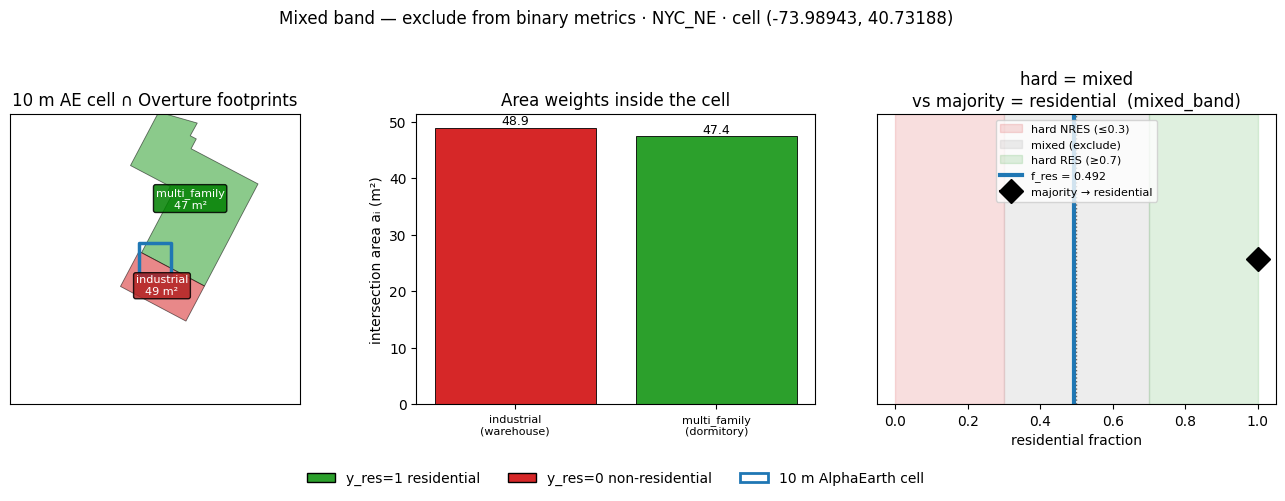

Wrote /data/users/kv133/Alpha-Earth-Embeddings-Research/outputs/ae_f_res/figures/scenario_-73p989426_40p73188.png


**Mixed band — exclude from binary metrics** — `industrial` aᵢ=48.9 m², `multi_family` aᵢ=47.4 m² → **f_res=0.492** → hard=`mixed` (majority would say `residential`)

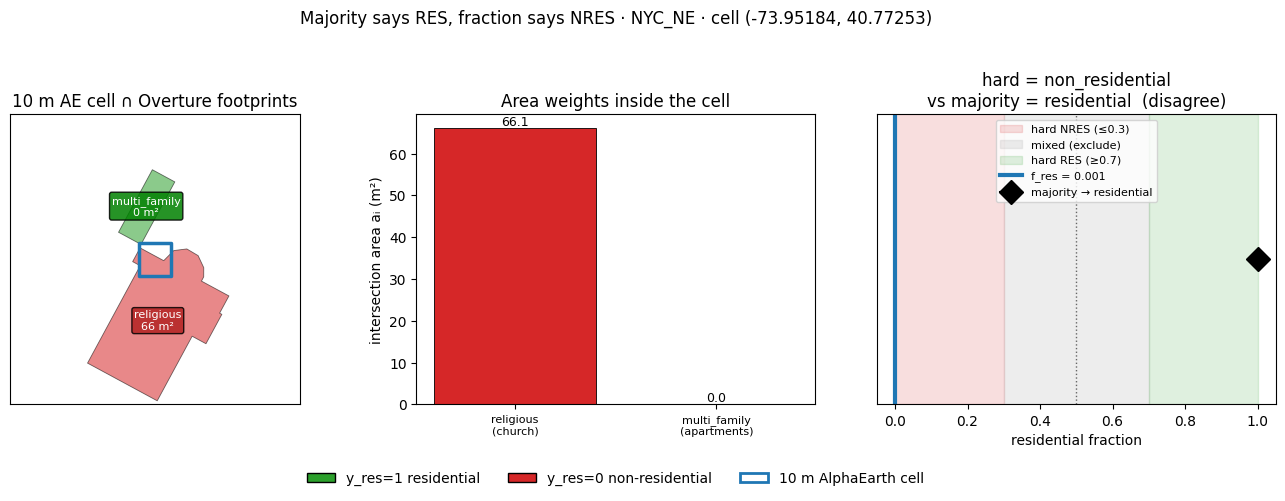

Wrote /data/users/kv133/Alpha-Earth-Embeddings-Research/outputs/ae_f_res/figures/scenario_-73p951839_40p772533.png


**Majority says RES, fraction says NRES** — `religious` aᵢ=66.1 m², `multi_family` aᵢ=0.0 m² → **f_res=0.001** → hard=`non_residential` (majority would say `residential`)

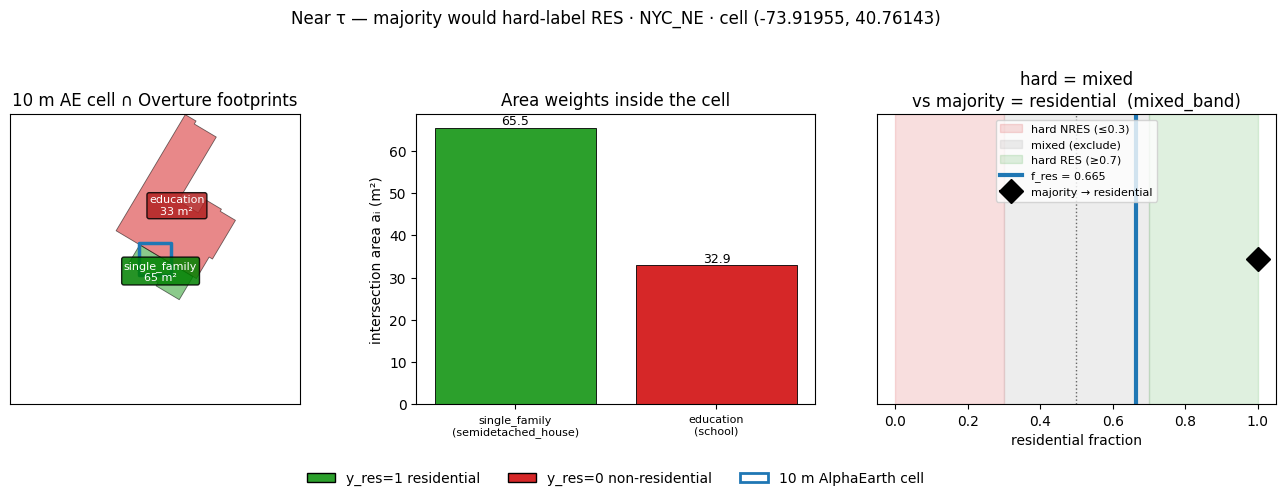

Wrote /data/users/kv133/Alpha-Earth-Embeddings-Research/outputs/ae_f_res/figures/scenario_-73p919552_40p761425.png


**Near τ — majority would hard-label RES** — `single_family` aᵢ=65.5 m², `education` aᵢ=32.9 m² → **f_res=0.665** → hard=`mixed` (majority would say `residential`)

In [4]:
def plot_cell_scenario(key: str, title_suffix: str, out_png: Path):
    rec = mixed_cells.loc[mixed_cells["key"] == key].iloc[0]
    info = details_by_key[key]
    parts = info["parts"]
    cell_geom = info["cell_geom"]

    # local map frame in UTM
    pad = 40
    minx, miny, maxx, maxy = cell_geom.bounds
    bbox = (minx - pad, miny - pad, maxx + pad, maxy + pad)
    nearby = gdf_m.cx[bbox[0]:bbox[2], bbox[1]:bbox[3]]

    fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.4))

    # --- panel 1: map ---
    ax = axes[0]
    for _, b in nearby.iterrows():
        col = RES_COLOR if b["y_res"] == 1 else NRES_COLOR
        alpha = 0.55 if b["id"] in {p["building_id"] for p in parts} else 0.15
        gpd.GeoSeries([b.geometry], crs=UTM).plot(ax=ax, facecolor=col, edgecolor="k",
                                                   linewidth=0.6, alpha=alpha)
    gpd.GeoSeries([cell_geom], crs=UTM).plot(
        ax=ax, facecolor="none", edgecolor=CELL_EDGE, linewidth=2.5
    )
    # label contributing buildings
    for p in parts:
        g = gdf_m.loc[gdf_m["id"] == p["building_id"]].geometry.iloc[0]
        c = g.centroid
        ax.annotate(
            f"{p['label']}\n{p['a_i']:.0f} m²",
            xy=(c.x, c.y), ha="center", va="center", fontsize=8,
            color="white",
            bbox=dict(boxstyle="round,pad=0.2", fc=("green" if p["y_res"] else "firebrick"), alpha=0.85),
        )
    ax.set_xlim(bbox[0], bbox[2])
    ax.set_ylim(bbox[1], bbox[3])
    ax.set_aspect("equal")
    ax.set_title("10 m AE cell ∩ Overture footprints")
    ax.set_xticks([]); ax.set_yticks([])

    # --- panel 2: area bars ---
    ax = axes[1]
    names = [f"{p['label']}\n({p['class']})" for p in parts]
    areas = [p["a_i"] for p in parts]
    colors = [RES_COLOR if p["y_res"] else NRES_COLOR for p in parts]
    ax.bar(range(len(parts)), areas, color=colors, edgecolor="k", linewidth=0.6)
    ax.set_xticks(range(len(parts)))
    ax.set_xticklabels(names, fontsize=8)
    ax.set_ylabel("intersection area aᵢ (m²)")
    ax.set_title("Area weights inside the cell")
    for i, a in enumerate(areas):
        ax.text(i, a, f"{a:.1f}", ha="center", va="bottom", fontsize=9)

    # --- panel 3: decision ---
    ax = axes[2]
    f = float(rec["f_res"])
    ax.axvspan(0, 0.3, color=NRES_COLOR, alpha=0.15, label="hard NRES (≤0.3)")
    ax.axvspan(0.3, 0.7, color="#bbbbbb", alpha=0.25, label="mixed (exclude)")
    ax.axvspan(0.7, 1.0, color=RES_COLOR, alpha=0.15, label="hard RES (≥0.7)")
    ax.axvline(f, color=CELL_EDGE, lw=3, label=f"f_res = {f:.3f}")
    ax.axvline(0.5, color="0.4", ls=":", lw=1)
    # majority marker
    maj_x = 1.0 if rec["majority_count_label"] == "residential" else 0.0
    ax.plot(maj_x, 0.5, marker="D", markersize=12, color="k", label=f"majority → {rec['majority_count_label']}")
    ax.set_xlim(-0.05, 1.05)
    ax.set_ylim(0, 1)
    ax.set_yticks([])
    ax.set_xlabel("residential fraction")
    ax.set_title(
        f"hard = {rec['hard_label']}\n"
        f"vs majority = {rec['majority_count_label']}  ({rec['fraction_vs_majority']})"
    )
    ax.legend(loc="upper center", fontsize=8, frameon=True)

    fig.suptitle(
        f"{title_suffix} · {AOI} · cell ({rec['pixel_lon']:.5f}, {rec['pixel_lat']:.5f})",
        y=1.03,
    )
    fig.legend(
        handles=[
            Patch(facecolor=RES_COLOR, edgecolor="k", label="y_res=1 residential"),
            Patch(facecolor=NRES_COLOR, edgecolor="k", label="y_res=0 non-residential"),
            Patch(facecolor="none", edgecolor=CELL_EDGE, linewidth=2, label="10 m AlphaEarth cell"),
        ],
        loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.08), frameon=False,
    )
    fig.tight_layout()
    fig.savefig(out_png, dpi=150, bbox_inches="tight")
    plt.show()
    return rec


# Pick: (1) mixed band, (2) majority disagrees with hard NRES, (3) near 50/50 mixed
picks = []
band = mixed_cells[mixed_cells["hard_label"] == "mixed"].sort_values("f_res")
# prefer mid-band with decent area
if len(band):
    mid = band.iloc[(band["f_res"] - 0.5).abs().argsort().iloc[0]]
    picks.append((mid["key"], "Mixed band — exclude from binary metrics"))
disagree = mixed_cells[mixed_cells["fraction_vs_majority"] == "disagree"].copy()
# classic trap: majority RES but f_res ≤ 0.3
trap = disagree[disagree["hard_label"] == "non_residential"].sort_values("f_res")
if len(trap):
    picks.append((trap.iloc[0]["key"], "Majority says RES, fraction says NRES"))
# another mixed with f_res closer to τ
if len(band) > 1:
    near_tau = band.sort_values("f_res", ascending=False).iloc[0]
    if near_tau["key"] not in {p[0] for p in picks}:
        picks.append((near_tau["key"], "Near τ — majority would hard-label RES"))

scenario_rows = []
for key, title in picks[:3]:
    png = FIG / f"scenario_{key.replace('.', 'p')[:40]}.png"
    rec = plot_cell_scenario(key, title, png)
    print("Wrote", png)
    parts = details_by_key[key]["parts"]
    display(Markdown(
        f"**{title}** — "
        + ", ".join(f"`{p['label']}` aᵢ={p['a_i']:.1f} m²" for p in parts)
        + f" → **f_res={rec['f_res']:.3f}** → hard=`{rec['hard_label']}` "
        + f"(majority would say `{rec['majority_count_label']}`)"
    ))
    scenario_rows.append(rec.to_dict())

pd.DataFrame(scenario_rows).to_parquet(OUT / "demo_scenarios.parquet", index=False)


## 4. How often does this bite in NYC?


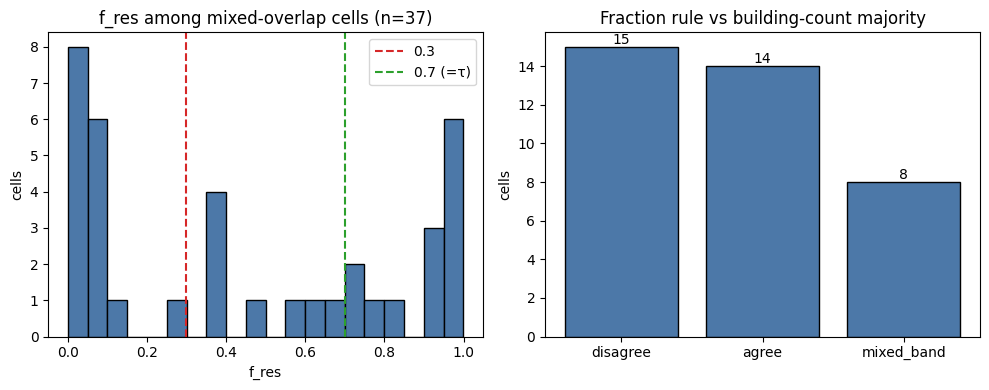

Wrote /data/users/kv133/Alpha-Earth-Embeddings-Research/outputs/ae_f_res/figures/f_res_summary.png
{
  "doc": "docs/residential_definition_v1.md",
  "rule": "f_res = area-weighted mean of y_res; tau=0.7; mixed band excluded",
  "aoi": "NYC_NE",
  "n_buildings": 1327,
  "n_unique_ae_cells_inside": 19422,
  "n_cells_with_both_classes": 37,
  "hard_label_counts": {
    "non_residential": 16,
    "residential": 13,
    "mixed": 8
  },
  "fraction_vs_majority": {
    "disagree": 15,
    "agree": 14,
    "mixed_band": 8
  },
  "note": "Building-level y_res is already used in training. This notebook demonstrates cell-level f_res (Track B) which is defined but not yet in the training pipeline.",
  "paths": {
    "mixed_cells": "outputs/ae_f_res/mixed_ae_cells.parquet",
    "scenarios": "outputs/ae_f_res/demo_scenarios.parquet",
    "figures": "outputs/ae_f_res/figures"
  }
}


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].hist(mixed_cells["f_res"], bins=20, color="#4c78a8", edgecolor="k")
axes[0].axvline(0.3, color=NRES_COLOR, ls="--", label="0.3")
axes[0].axvline(0.7, color=RES_COLOR, ls="--", label="0.7 (=τ)")
axes[0].set_xlabel("f_res")
axes[0].set_ylabel("cells")
axes[0].set_title(f"f_res among mixed-overlap cells (n={len(mixed_cells)})")
axes[0].legend()

vc = mixed_cells["fraction_vs_majority"].value_counts()
axes[1].bar(vc.index.astype(str), vc.values, color="#4c78a8", edgecolor="k")
axes[1].set_title("Fraction rule vs building-count majority")
axes[1].set_ylabel("cells")
for i, v in enumerate(vc.values):
    axes[1].text(i, v, str(v), ha="center", va="bottom")
fig.tight_layout()
summary_png = FIG / "f_res_summary.png"
fig.savefig(summary_png, dpi=140, bbox_inches="tight")
plt.show()
print("Wrote", summary_png)

snapshot = {
    "doc": "docs/residential_definition_v1.md",
    "rule": "f_res = area-weighted mean of y_res; tau=0.7; mixed band excluded",
    "aoi": AOI,
    "n_buildings": int(len(gdf_m)),
    "n_unique_ae_cells_inside": int(len(cg)),
    "n_cells_with_both_classes": int(len(mixed_cells)),
    "hard_label_counts": mixed_cells["hard_label"].value_counts().to_dict(),
    "fraction_vs_majority": mixed_cells["fraction_vs_majority"].value_counts().to_dict(),
    "note": (
        "Building-level y_res is already used in training. "
        "This notebook demonstrates cell-level f_res (Track B) which is defined but not yet in the training pipeline."
    ),
    "paths": {
        "mixed_cells": "outputs/ae_f_res/mixed_ae_cells.parquet",
        "scenarios": "outputs/ae_f_res/demo_scenarios.parquet",
        "figures": "outputs/ae_f_res/figures",
    },
}
(OUT / "snapshot.json").write_text(json.dumps(snapshot, indent=2))
print(json.dumps(snapshot, indent=2))


## 5. Takeaways

1. **Building GT** (`y_res`) is what we train on today.
2. **Cell GT** (`f_res`) is needed when the unit of prediction is a **10 m AlphaEarth pixel**.
3. Majority-by-building-count fails when one large NRES footprint and one small RES footprint share a cell (or vice versa) — fraction + τ fixes that and creates an explicit **mixed** bucket.
4. Cell-table materialization is still TBD in the training pipeline; this notebook is the worked example.

**Related.** Notebook 11 = GHSL majority under a *building*. This notebook = Overture area fraction under an *AE cell*.
